In [6]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV

In [7]:
X_train = pd.read_csv('../dataset/precessed/X_train.csv')
X_test = pd.read_csv('../dataset/precessed/X_test.csv')
y_train = pd.read_csv('../dataset/precessed/y_train.csv')
y_test = pd.read_csv('../dataset/precessed/y_test.csv')

In [8]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'DecisionTreeClassifier': DecisionTreeClassifier(random_state=42),
    'RandomForestClassifier': RandomForestClassifier(random_state=42),
    'GradientBoostingClassifier': GradientBoostingClassifier(random_state=42),
    'HistGradientBoostingClassifier': HistGradientBoostingClassifier(random_state=42)
}

In [9]:
result = []

for name, model in models.items():

    pipeline = Pipeline([
        ('smote', SMOTE(random_state=42)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    probability = pipeline.predict_proba(X_test)[:,1]

    result.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 score': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probability)
    })

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: Data

In [10]:
result_df = pd.DataFrame(result)

result_df.sort_values(
    ascending=False,
    by='ROC AUC'
)

result_report = result_df.copy()

result_report.to_csv(
    '../report/result_report.csv',
    index=False
)

In [11]:
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

## Machine Learning Pipeline

An **Imbalanced-learn Pipeline** is created to combine **SMOTE** and **Random Forest** into a single workflow.

- **SMOTE** balances the minority class by generating synthetic samples.
- **Random Forest** learns from the balanced training data.
- The pipeline ensures that SMOTE is applied **only during training**, preventing data leakage and enabling reliable cross-validation.

This workflow follows best practices for imbalanced classification tasks such as credit card fraud detection.

In [12]:
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}

In [13]:
grid_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=5,
    n_jobs=1,
    random_state=42,
    verbose=2
)

grid_search.fit(X_train, y_train)

print('Best Parameters:')
print(grid_search.best_estimator_)

print('\nBest ROC AUC:')
print(grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


[CV] END classifier__max_depth=30, classifier__max_features=log2, classifier__min_samples_leaf=2, classifier__min_samples_split=5, classifier__n_estimators=100; total time= 2.8min


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


[CV] END classifier__max_depth=30, classifier__max_features=log2, classifier__min_samples_leaf=2, classifier__min_samples_split=5, classifier__n_estimators=100; total time= 3.0min


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


... (193 outputs left out)

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


[CV] END classifier__max_depth=10, classifier__max_features=sqrt, classifier__min_samples_leaf=2, classifier__min_samples_split=5, classifier__n_estimators=100; total time= 2.8min


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best Parameters:
Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('classifier',
                 RandomForestClassifier(max_depth=30, min_samples_leaf=2,
                                        min_samples_split=5, n_estimators=300,
                                        random_state=42))])

Best ROC AUC:
0.9860868919447805


In [14]:
best_params = (
    pd.DataFrame(
        grid_search.best_params_.items(),
        columns=['Parameter', 'Value']
    )
)

best_params.to_csv(
    '../report/best_params.csv',
    index=False
)

print(best_params)

best_model = grid_search.best_estimator_

print(best_model)

predictions = best_model.predict(X_test)
probability = best_model.predict_proba(X_test)[:, 1]

                       Parameter Value
0       classifier__n_estimators   300
1  classifier__min_samples_split     5
2   classifier__min_samples_leaf     2
3       classifier__max_features  sqrt
4          classifier__max_depth    30
Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('classifier',
                 RandomForestClassifier(max_depth=30, min_samples_leaf=2,
                                        min_samples_split=5, n_estimators=300,
                                        random_state=42))])


In [15]:
# Evaluation
print("Accuracy :", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall   :", recall_score(y_test, predictions))
print("F1 Score :", f1_score(y_test, predictions))
print("ROC AUC  :", roc_auc_score(y_test, probability))

Accuracy : 0.999420666409185
Precision: 0.8282828282828283
Recall   : 0.8367346938775511
F1 Score : 0.8324873096446701
ROC AUC  : 0.9718959773695635


In [16]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.84      0.83        98

    accuracy                           1.00     56962
   macro avg       0.91      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962



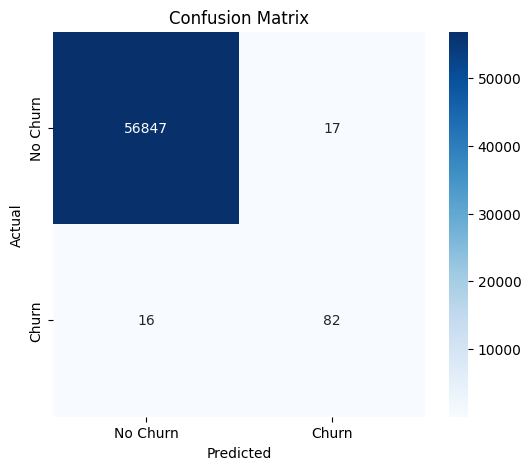

In [17]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

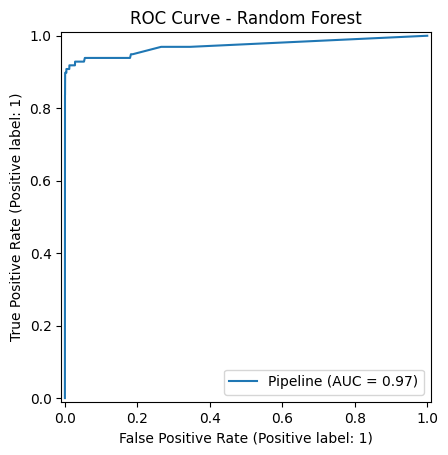

In [18]:
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title('ROC Curve - Random Forest')
plt.show()

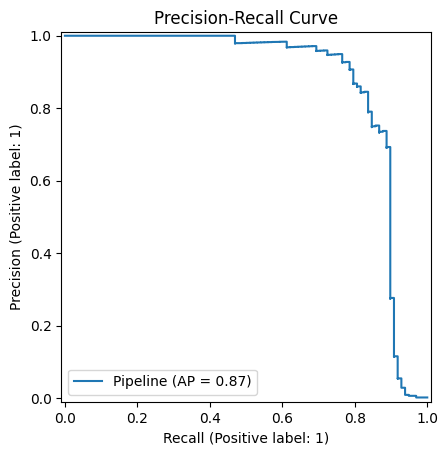

In [19]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title('Precision-Recall Curve')
plt.show()

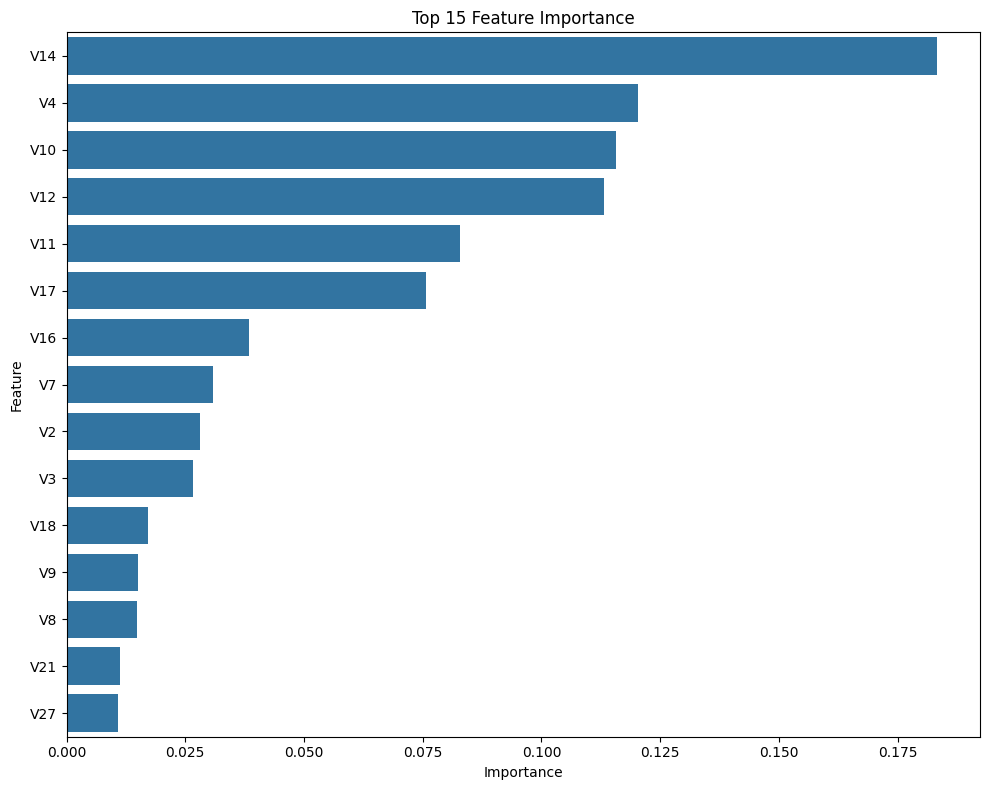

In [20]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_model.named_steps['classifier'].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance_report = feature_importance.copy()

feature_importance_report.to_csv(
    '../report/feature_importance_report.csv',
    index=False
)

plt.figure(figsize=(10,8))
sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)
plt.title('Top 15 Feature Importance')
plt.tight_layout()
plt.show()

In [21]:
joblib.dump(best_model, '../saved_models/random_forest.pkl')

print('Model saved successfully.')

Model saved successfully.


In [22]:

np.save('../report/y_test.npy', y_test.values.ravel())
np.save('../report/y_pred.npy', predictions)
np.save('../report/y_prob.npy', probability)

In [23]:
pd.DataFrame(
    cm,
    index=["Actual Legit", "Actual Fraud"],
    columns=["Pred Legit", "Pred Fraud"]
).to_csv(
    '../report/confusion_matrix.csv'
)